# Analysis Portion of Project

In [2]:
import numpy as np
import math
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [3]:
#loading in pickle file, then converting to data frame
df2 = pd.read_pickle("cleanDataBase.pkl")
df2 = pd.DataFrame(df2)
df2

,Age,Gender,Marital Status,Occupation,Monthly Income,Educational Qualifications,Family size,Customer Type,latitude,longitude,Pin code,Output,Feedback
0,20,Female,Single,Student,No Income,Post Graduate,4,Frequent,12.9766,77.5993,560001,Yes,Positive
1,24,Female,Single,Student,Below Rs.10000,Graduate,3,Regular,12.9770,77.5773,560009,Yes,Positive
2,22,Male,Single,Student,Below Rs.10000,Post Graduate,3,Regular,12.9551,77.6593,560017,Yes,Negative
3,22,Female,Single,Student,No Income,Graduate,6,Frequent,12.9473,77.5616,560019,Yes,Positive
4,22,Male,Single,Student,Below Rs.10000,Post Graduate,4,Frequent,12.9850,77.5533,560010,Yes,Positive
...,...,...,...,...,...,...,...,...,...,...,...,...,...
383,23,Female,Single,Student,No Income,Post Graduate,2,Regular,12.9766,77.5993,560001,Yes,Positive
384,23,Female,Single,Student,No Income,Post Graduate,4,Frequent,12.9854,77.7081,560048,Yes,Positive
385,22,Female,Single,Student,No Income,Post Graduate,5,Frequent,12.9850,77.5533,560010,Yes,Positive
386,23,Male,Single,Student,Below Rs.10000,Post Graduate,2,Regular,12.9770,77.5773,560009,Yes,Positive


<Axes: >

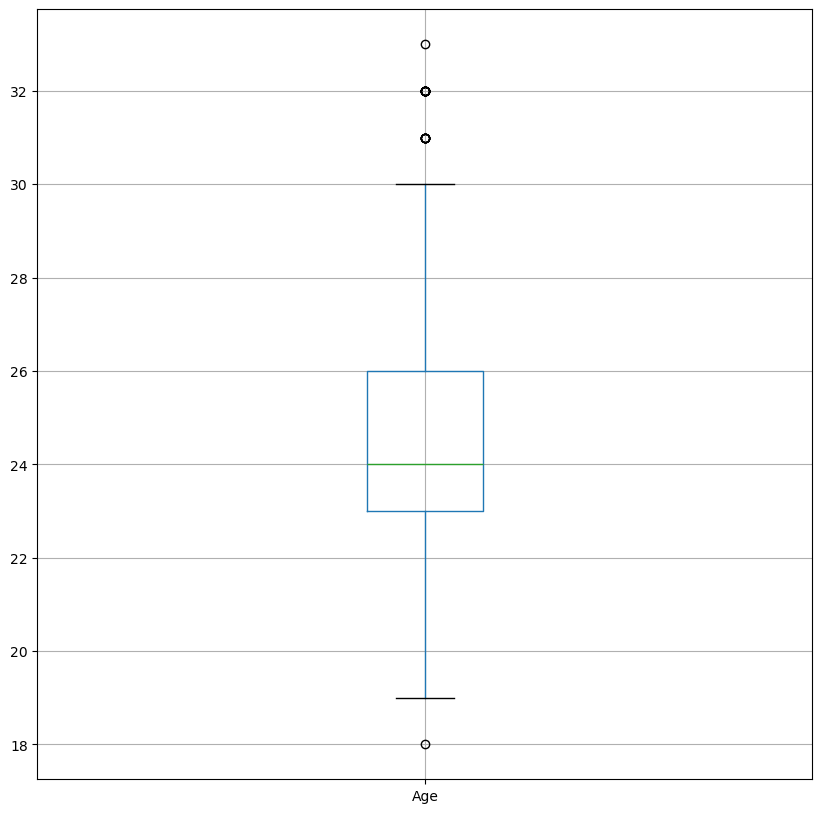

In [4]:
df2.boxplot('Age', figsize = (10,10))

In [5]:
#Checking for data spread of age category
Q1A = df2['Age'].quantile(.25)
Q2A = df2['Age'].quantile(.50)
Q3A = df2['Age'].quantile(.75)

print(Q1A,Q2A,Q3A)

23.0 24.0 26.0


In [6]:
#calculating interquartile range

IQRA = Q3A - Q1A
IQRA



3.0

In [7]:
#finding outlier whisker level

out_highA = Q3A+1.5*IQRA
out_lowA = Q1A-1.5*IQRA

print(out_highA)
print(out_lowA)

30.5
18.5


In [8]:
#removing outliers from database

outliers_A =(df2['Age']< out_lowA) | (df2['Age'] > out_highA)

df2[outliers_A]


,Age,Gender,Marital Status,Occupation,Monthly Income,Educational Qualifications,Family size,Customer Type,latitude,longitude,Pin code,Output,Feedback
37,32,Female,Prefer not to say,House wife,No Income,Graduate,5,Frequent,12.9820,77.6256,560008,Yes,Negative
58,31,Male,Married,Employee,More than 50000,Ph.D,5,Frequent,12.9119,77.6446,560102,Yes,Positive
99,32,Female,Married,House wife,No Income,Uneducated,3,Regular,13.0140,77.5658,560012,No,Positive
109,18,Male,Single,Student,No Income,Graduate,5,Frequent,12.9635,77.5821,560002,Yes,Positive
116,31,Female,Married,House wife,No Income,School,5,Frequent,13.0289,77.5400,560022,Yes,Positive
118,32,Female,Married,Employee,25001 to 50000,Graduate,5,Frequent,12.9261,77.6221,560034,Yes,Positive
123,32,Male,Married,Employee,More than 50000,Ph.D,5,Frequent,12.9635,77.5821,560002,Yes,Negative
131,32,Female,Married,Employee,More than 50000,Graduate,1,New,13.0019,77.5713,560003,No,Positive
137,33,Male,Married,Employee,More than 50000,Ph.D,5,Frequent,12.9980,77.6227,560005,No,Negative
148,32,Male,Married,Employee,10001 to 25000,Graduate,4,Frequent,12.9783,77.6408,560038,Yes,Positive


In [9]:
#Converting categorical values into numbers using index

income_rank = {
    'No Income': 0,
    'Below Rs.10000': 1,
    '10001 to 25000': 2,
    '25001 to 50000': 3,
    'More than 50000': 4,
}

df2['Income Rank'] = df2['Monthly Income'].str.strip().map(income_rank)

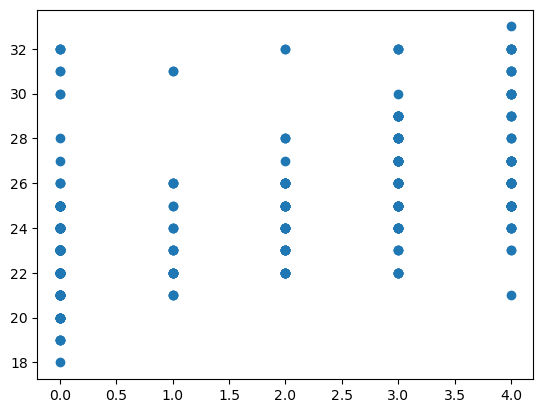

In [10]:
plt.scatter(df2['Income Rank'], df2['Age'])
plt.show()

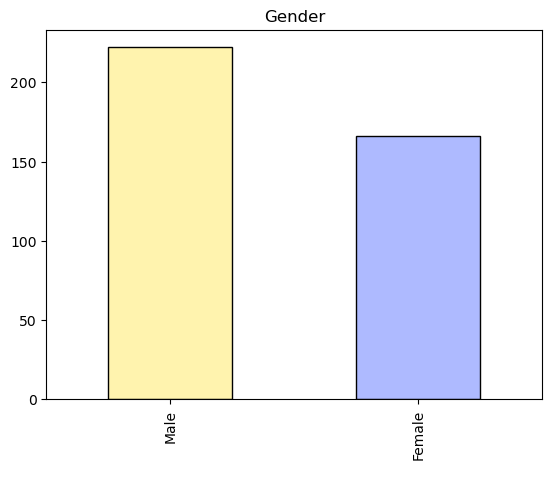

In [87]:
df2['Gender'].value_counts().plot(
    kind='bar', 
    color=['#fff3ae', '#aebaff'], 
    edgecolor='black')
plt.xlabel(' ')
plt.title('Gender')

plt.show()

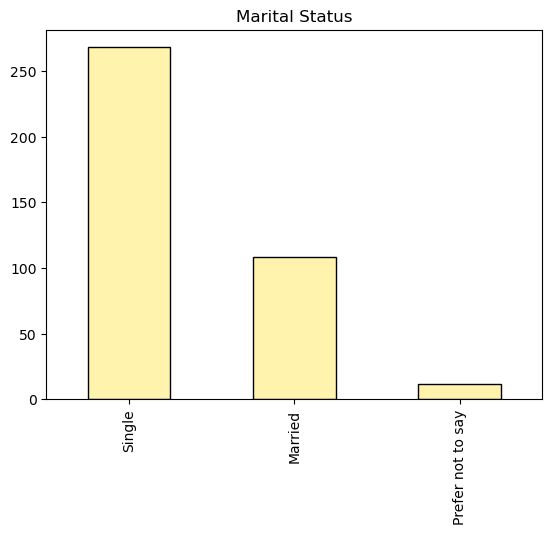

In [19]:
df2['Marital Status'].value_counts().plot(
    kind='bar', 
    color=['#fff3ae'], 
    edgecolor='black')
plt.xlabel(' ')
plt.title('Marital Status')

plt.show()

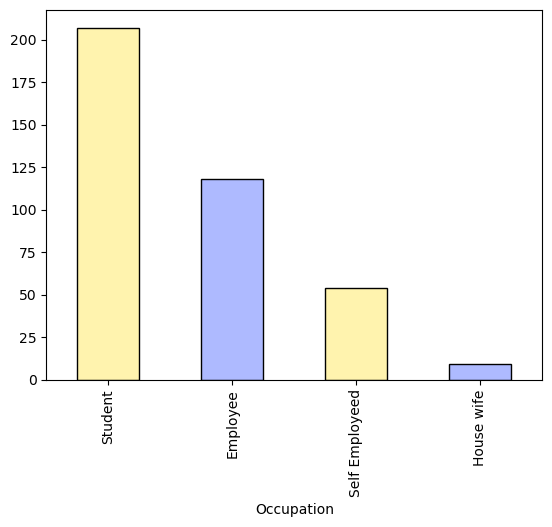

In [21]:
df2['Occupation'].value_counts().plot(
    kind='bar', 
    color=['#fff3ae', '#aebaff'], 
    edgecolor='black')
plt.show()

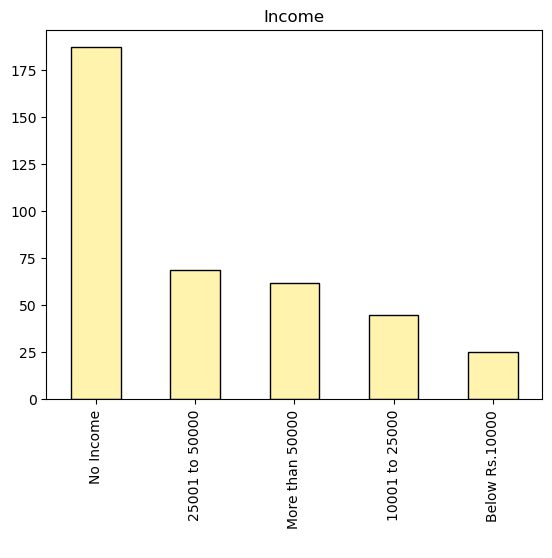

In [20]:
df2['Monthly Income'].value_counts().plot(
    kind='bar', 
    color=['#fff3ae'], 
    edgecolor='black')
plt.xlabel(' ')
plt.title('Income')
plt.show()

### Initial Analysis 

after taking a look a some basic categorical variables in our database, we've determined the following factors

mean age is 24.6, with q2 and q3 being 24 and 26 respectively, this is in line with a majority of the the sample subjects being students.

we see that no income is the most common reported salary, making sense among students who may be living on aid or other finanical supports, along with casual labor/gig econonmy roles from time to time .

Along with this we see reports of high distirbution of males in the dataset, along with a majority of consumers being single.

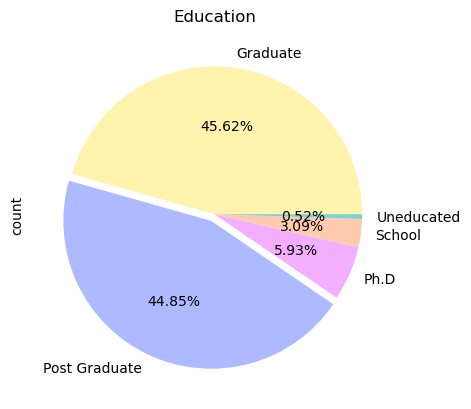

In [45]:
df2['Educational Qualifications'].value_counts().plot(
    kind='pie',
    colors=['#fff3ae', '#aebaff', '#f3aeff', '#ffcbae', '#7ed0d2'],
    explode = (0,0.05,0,0,0),
    autopct = '%1.2f%%')
plt.title('Education')
plt.show()

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


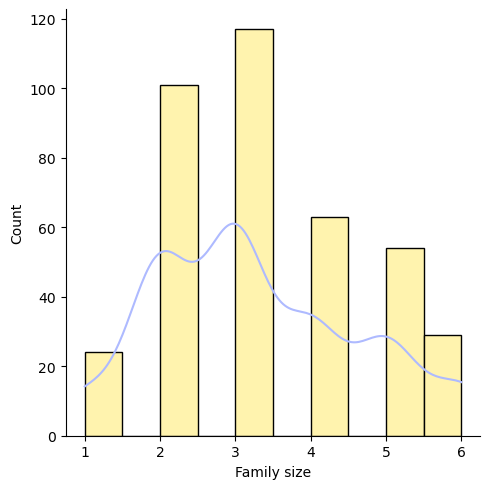

In [56]:
sns.displot(df2['Family size'], color='#aebaff' , edgecolor = 'black', facecolor = '#fff3ae', kde = True)
plt.show()

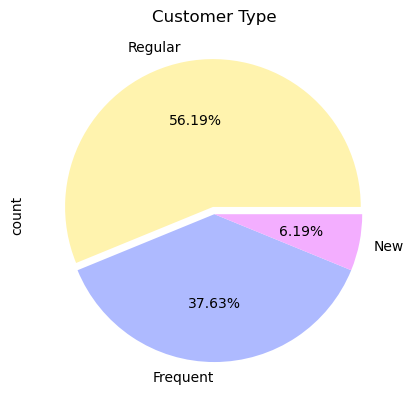

In [46]:
df2['Customer Type'].value_counts().plot(
    kind='pie',
 colors=['#fff3ae', '#aebaff', '#f3aeff'],
    explode = (0.05,0,0),
    autopct = '%1.2f%%')
plt.title('Customer Type')
plt.show()

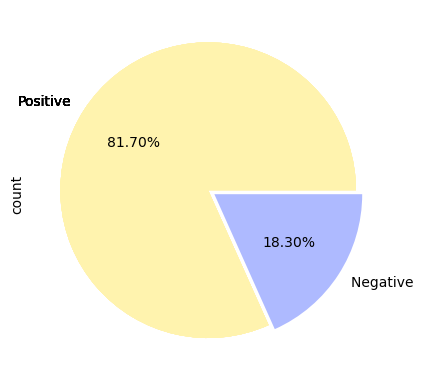

In [44]:
df2['Feedback'].value_counts().plot(
    kind='pie', 
    colors=['#fff3ae', '#aebaff', '#f3aeff'] , 
    explode = (0.05,0),
    autopct = '%1.2f%%')
plt.show()

### further analysis

however being single, poor, and unemployed does not seem to stop active grocery pruchases among consumers.
with over 50% being regular consumers, and nearly 1/3 being frequent. There may be bias in the data as frequent/regular consumers would be more likely to complete surveys and register for reward programs. 

When looking among the data we can also see that a small portion of consumers are undeducated, or have not finished a secondary education.

This suggest that the neighborhood where the store is located, may be a student area, or popular among young adults.

Finally, consumers have a positive perception of the store, but we need to mitigate bias of survey completion.
In this case both selection and social desirability bias may be corrupting the data.

The last peice of information is family size, with a majority living in a 2-4 person household.
meaning that many of the students are likely from a 2 parent household, with 1-2 siblings as well.

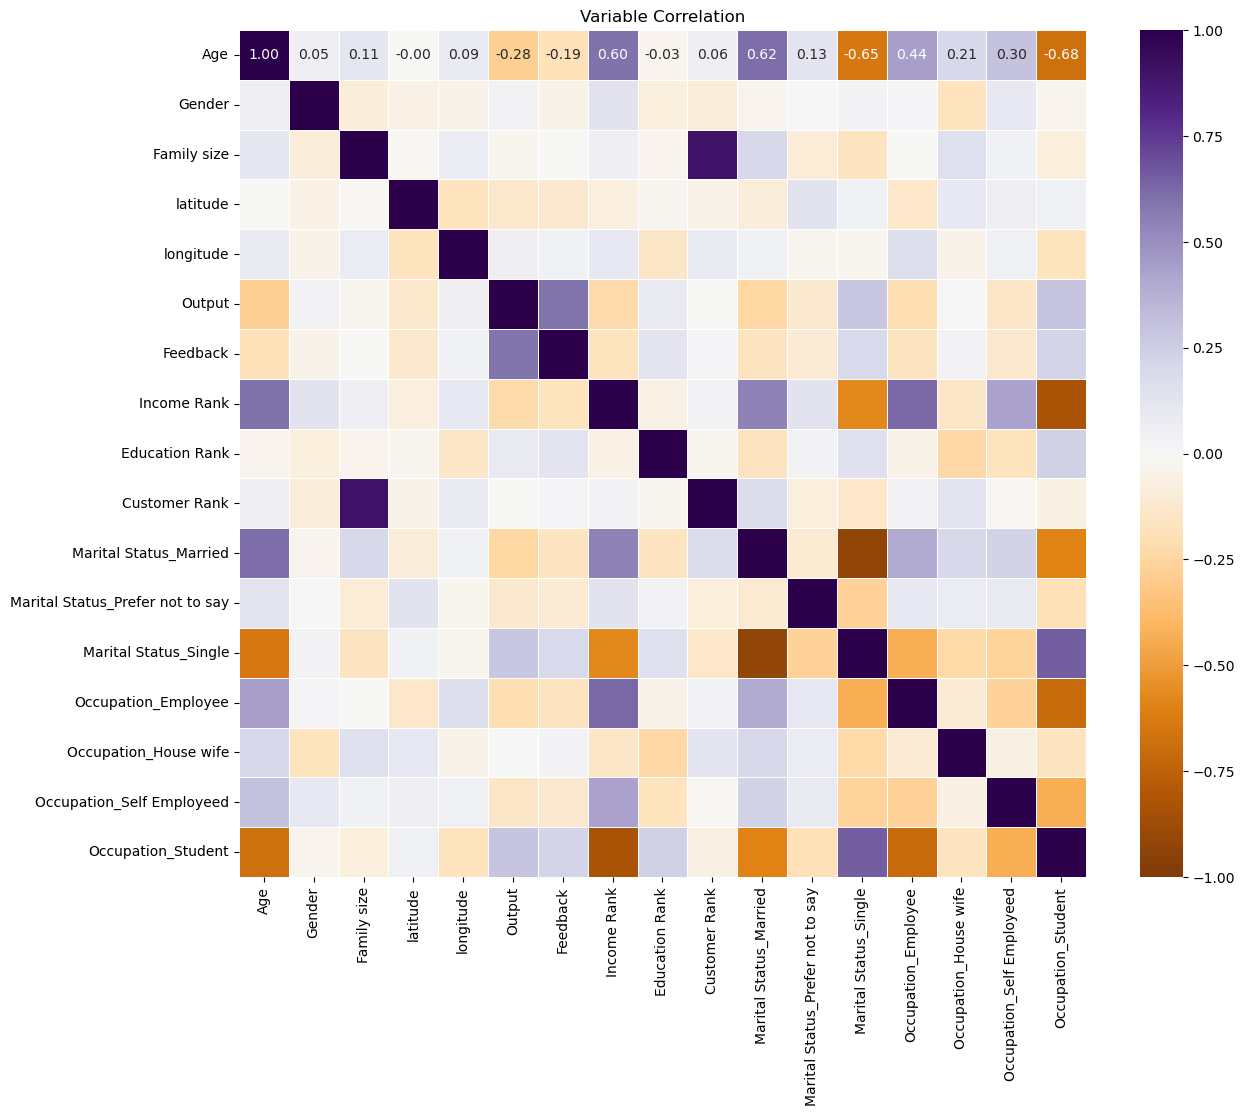

In [85]:
income_rank = {'No Income': 0, 'Below Rs.10000': 1, '10001 to 25000': 2,
               '25001 to 50000': 3, 'More than 50000': 4}
edu_rank = {'Uneducated': 0, 'School': 1, 'Graduate': 2, 'Post Graduate': 3, 'Ph.D': 4}
customer_rank = {'New': 0, 'Regular': 1, 'Frequent': 2}

dfc = df2.copy()

"""reassigning values in dictionary for income rank, edu rank, and customer rank columns, as sns.heatmap() and pd.corr()
cannot process strings
    """
# strip stray whitespace (e.g. 'Negative ') in every text column
for col in dfc.columns:
    if not pd.api.types.is_numeric_dtype(dfc[col]):
        dfc[col] = dfc[col].astype(str).str.strip()

# ordinal
dfc['Income Rank'] = dfc['Monthly Income'].map(income_rank)
dfc['Education Rank'] = dfc['Educational Qualifications'].map(edu_rank)
dfc['Customer Rank'] = dfc['Customer Type'].map(customer_rank)

# binary
dfc['Gender'] = dfc['Gender'].map({'Female': 0, 'Male': 1})
dfc['Output'] = dfc['Output'].map({'No': 0, 'Yes': 1})
dfc['Feedback'] = dfc['Feedback'].map({'Negative': 0, 'Positive': 1})

# nominal -> one-hot
dfc = pd.get_dummies(dfc, columns=['Marital Status', 'Occupation'], dtype=int)


# drop originals that were replaced, plus the Pin code identifier
dfc = dfc.drop(columns=['Monthly Income', 'Educational Qualifications',
                        'Customer Type', 'Pin code'])


corr = dfc.corr(method='spearman')

plt.figure(figsize=(14, 11))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='PuOr', center = 0 ,
            vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title('Variable Correlation')
plt.show()

### Reviewing Variable correlation ###

The following items seem to have a strong correlattion with one another, orange represent negative relationship while purple is positive, a strong correlation is when x >= 0.7 in terms of range

- **customer rank & family size**

 - **income rank & occupation**
 
- **Age & student status**

output and feedback border on the strong correlation level but are still moderate, while a majority of other factors are weak-moderate in terms of correlation wether positve or negative.

